In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from brainspace.mesh.mesh_creation import build_polydata
from nsbutils.plotting import plot_surf
from nsbutils.utils import unparcellate

from neuromodes import EigenSolver
from neuromodes.io import fetch_example_map, fetch_example_surf


In [2]:
surf, medmask = fetch_example_surf()
solver = EigenSolver(surf, medmask)

In [3]:
n_parcels = [10, 50, 100, 500]
parc = solver.make_parcellation(n_parcels, seed=0)
parc

array([[  8,  31, 100,  62],
       [  3,  47,  69, 263],
       [  3,  14,  70,  31],
       ...,
       [  6,  21,  47,  25],
       [  6,  21,  47,  25],
       [  6,  21,  47,  25]], shape=(29696, 4))

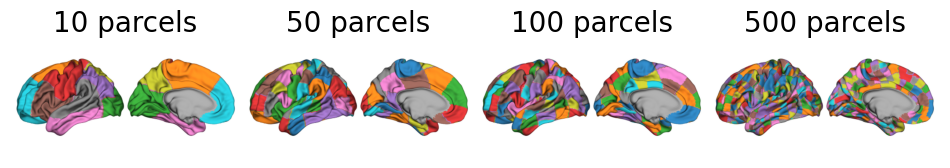

In [4]:
plot_surf(build_polydata(surf.v, surf.t), solver.unmask_data(parc), cmap="tab10", cbar=False, labels=[f"{n} parcels" for n in n_parcels])

10 parcels: 3 dangling vertices (0.01%)
50 parcels: 13 dangling vertices (0.04%)
100 parcels: 24 dangling vertices (0.08%)
500 parcels: 128 dangling vertices (0.43%)


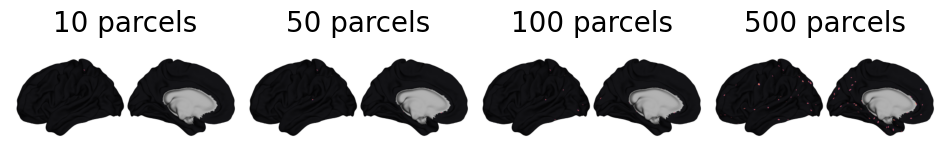

In [5]:
dangling = parc == -1
for i, n in enumerate(n_parcels):
    print(f"{n} parcels: {np.sum(dangling[:, i])} dangling vertices ({np.sum(dangling[:, i]) / len(dangling[:, i]) * 100:.2f}%)")
plot_surf(build_polydata(surf.v, surf.t), solver.unmask_data(dangling), cmap="inferno", cbar=False, labels=[f"{n} parcels" for n in n_parcels])

In [8]:
parcel_areas = [solver.parcellate(np.ones(solver.n_verts), parc[:, i], method="sum")[1:] for i in range(parc.shape[1])]

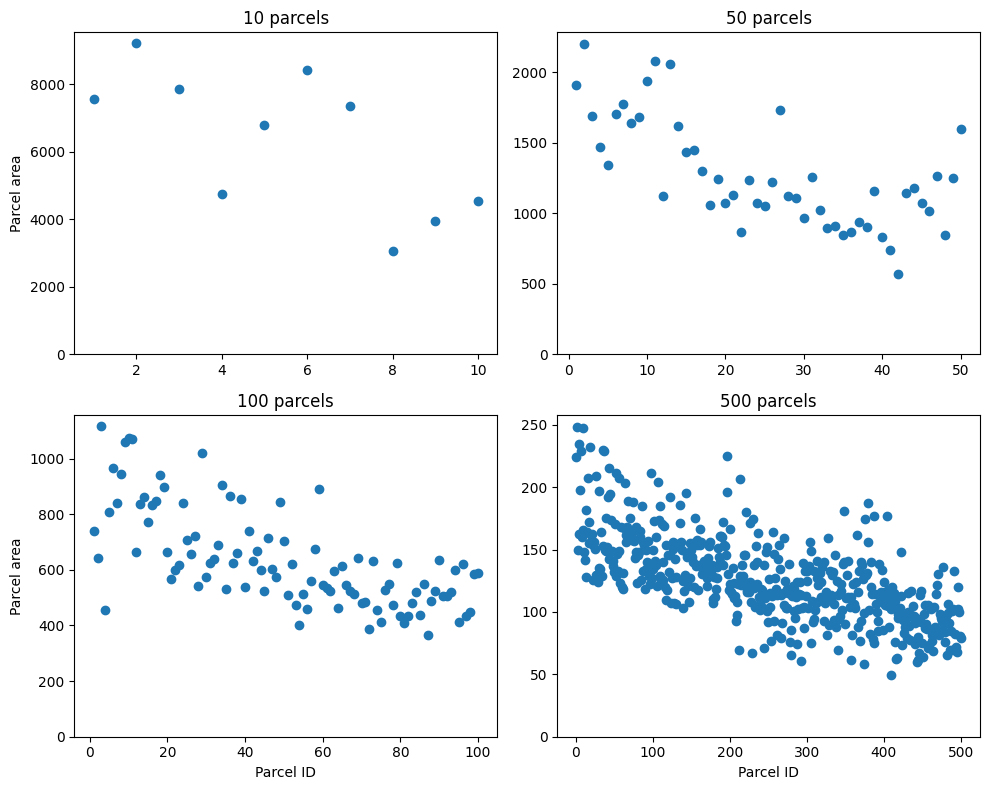

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
ax = ax.flatten()
for i, n in enumerate(n_parcels):
    ax[i].plot(np.arange(1, n + 1), parcel_areas[i], "o", label=f"{n} parcels")
    if i in [2, 3]:
        ax[i].set_xlabel("Parcel ID")
    ax[i].set_title(f"{n} parcels")
    if i in [0, 2]:
        ax[i].set_ylabel("Parcel area")
    ax[i].set_ylim(bottom=0)
plt.tight_layout()
plt.show()

In [54]:
myelinmap = fetch_example_map('myelinmap')[medmask]
myelinmap_parc = [solver.parcellate(myelinmap, parc[:, i], method="mean") for i in range(parc.shape[1])]
for i in range(parc.shape[1]):
    myelinmap_parc[i][0] = np.nan  # set dangling vertices to nan for plotter
myelinmap_unparc = np.stack([unparcellate(myelinmap_parc[i], parc[:, i]) for i in range(parc.shape[1])], axis=1)

c:\Users\ipop0003\neuromodes\.venv\Lib\site-packages\scipy\sparse\_base.py:970: RuntimeWarning: divide by zero encountered in divide
  return self.multiply(np.divide(1, other))


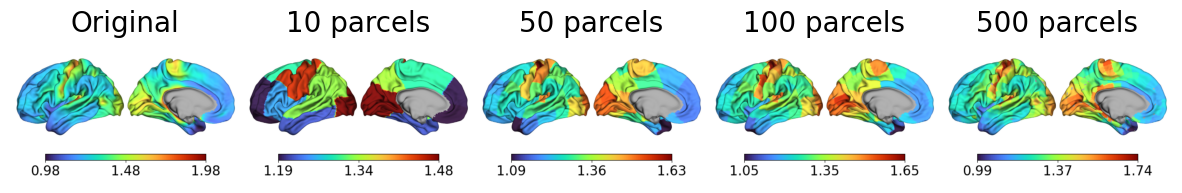

In [ ]:
plot_surf(build_polydata(surf.v, surf.t), solver.unmask_data(np.concatenate([myelinmap[:, None], myelinmap_unparc], axis=1)), cmap="turbo", cbar=True, labels=["Original"] + [f"{n} parcels" for n in n_parcels])

In [20]:
# compare to modal reconstruction
if not hasattr(solver, "emodes"):
    solver.solve(500)
recons = solver.reconstruct(myelinmap, mode_counts=n_parcels)

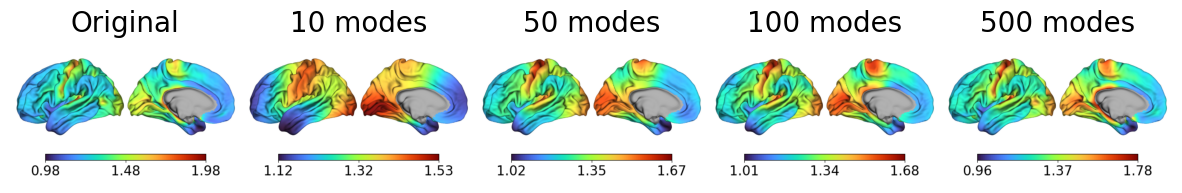

In [22]:
plot_surf(build_polydata(surf.v, surf.t), solver.unmask_data(np.concatenate([myelinmap[:, None], recons], axis=1)), cmap="turbo", cbar=True, labels=["Original"] + [f"{n} modes" for n in n_parcels])